In [243]:
import matplotlib.pyplot as plt
import numpy as np

Arshdeep Singh Kaur niub: 20709010 
Babaldeep Singh niub: 23516393

DISTRIBUTION OF WORK: Everything together

USE OF AI:
Help to make plots

We define the function and it's derivative. 

In [244]:
def f(x_1, x_2):  #We define our function f(x_1, x_2) = x_1^2 + x_2^2
    return x_1**2 + x_2**2

def df(x_1, x_2):  #We define the gradient of our function f(x_1, x_2)
    return np.array([2*x_1, 2*x_2])

Now, we define the algorithm of gradient descent:


In [245]:
def gradient_descent(df, starting_point, alpha, num_iterations):
    x_1, x_2 = map(float, starting_point)  
    points = [(x_1, x_2)]
    
    for i in range(num_iterations):
        gradient = df(x_1, x_2)
        x_1 -= alpha * gradient[0]
        x_2 -= alpha * gradient[1]
        points.append((x_1, x_2))
    
    return points

Now, having the algorithm of gradient descent, let's experiment with the function, using different starting points and different number of iterations. 

In [246]:
alpha = [0.01, 0.1, 1, 2] #We arbitrarily choose different learning rates to test the gradient descent algorithm.
num_iterations = [10, 50, 100, 1000] # We arbitrarily choose different numbers of iterations to test in the next experiments.

In [247]:
initial_points_1 = [(1,1), (2,2), (1,2), (2,1), (5,5)] # We arbitrally chose some initial points.
for i in initial_points_1:
    for j in alpha:
        print(f"Starting point = {i} and alpha = {j}")
        for k in num_iterations:
            min = gradient_descent(df, i, j, k)
            print(f"In the last iteration we got: x = ({min[-1][0]:.15f}, {min[-1][1]:.15f}) and is f(x) = {f(min[-1][0], min[-1][1]):.15f} with number of iterations = {k}")
        print()
# Remark that we don't say that we got the minimum, because it's not guaranteed, we just say that this is the last iteration.

Starting point = (1, 1) and alpha = 0.01
In the last iteration we got: x = (0.817072806887547, 0.817072806887547) and is f(x) = 1.335215943510189 with number of iterations = 10
In the last iteration we got: x = (0.364169680087117, 0.364169680087117) and is f(x) = 0.265239111789506 with number of iterations = 50
In the last iteration we got: x = (0.132619555894753, 0.132619555894753) and is f(x) = 0.035175893211443 with number of iterations = 100
In the last iteration we got: x = (0.000000001682967, 0.000000001682967) and is f(x) = 0.000000000000000 with number of iterations = 1000

Starting point = (1, 1) and alpha = 0.1
In the last iteration we got: x = (0.107374182400000, 0.107374182400000) and is f(x) = 0.023058430092137 with number of iterations = 10
In the last iteration we got: x = (0.000014272476927, 0.000014272476927) and is f(x) = 0.000000000407407 with number of iterations = 50
In the last iteration we got: x = (0.000000000203704, 0.000000000203704) and is f(x) = 0.0000000000

C:\Users\Arshdeep Singh\AppData\Local\Temp\ipykernel_28924\980923619.py:7: RuntimeWarning: overflow encountered in scalar multiply
  x_1 -= alpha * gradient[0]
C:\Users\Arshdeep Singh\AppData\Local\Temp\ipykernel_28924\980923619.py:8: RuntimeWarning: overflow encountered in scalar multiply
  x_2 -= alpha * gradient[1]
C:\Users\Arshdeep Singh\AppData\Local\Temp\ipykernel_28924\980923619.py:7: RuntimeWarning: invalid value encountered in scalar subtract
  x_1 -= alpha * gradient[0]
C:\Users\Arshdeep Singh\AppData\Local\Temp\ipykernel_28924\980923619.py:8: RuntimeWarning: invalid value encountered in scalar subtract
  x_2 -= alpha * gradient[1]
C:\Users\Arshdeep Singh\AppData\Local\Temp\ipykernel_28924\2281296617.py:5: RuntimeWarning: overflow encountered in scalar multiply
  return np.array([2*x_1, 2*x_2])


Now, we may look at the paths that gradient descent followed. 

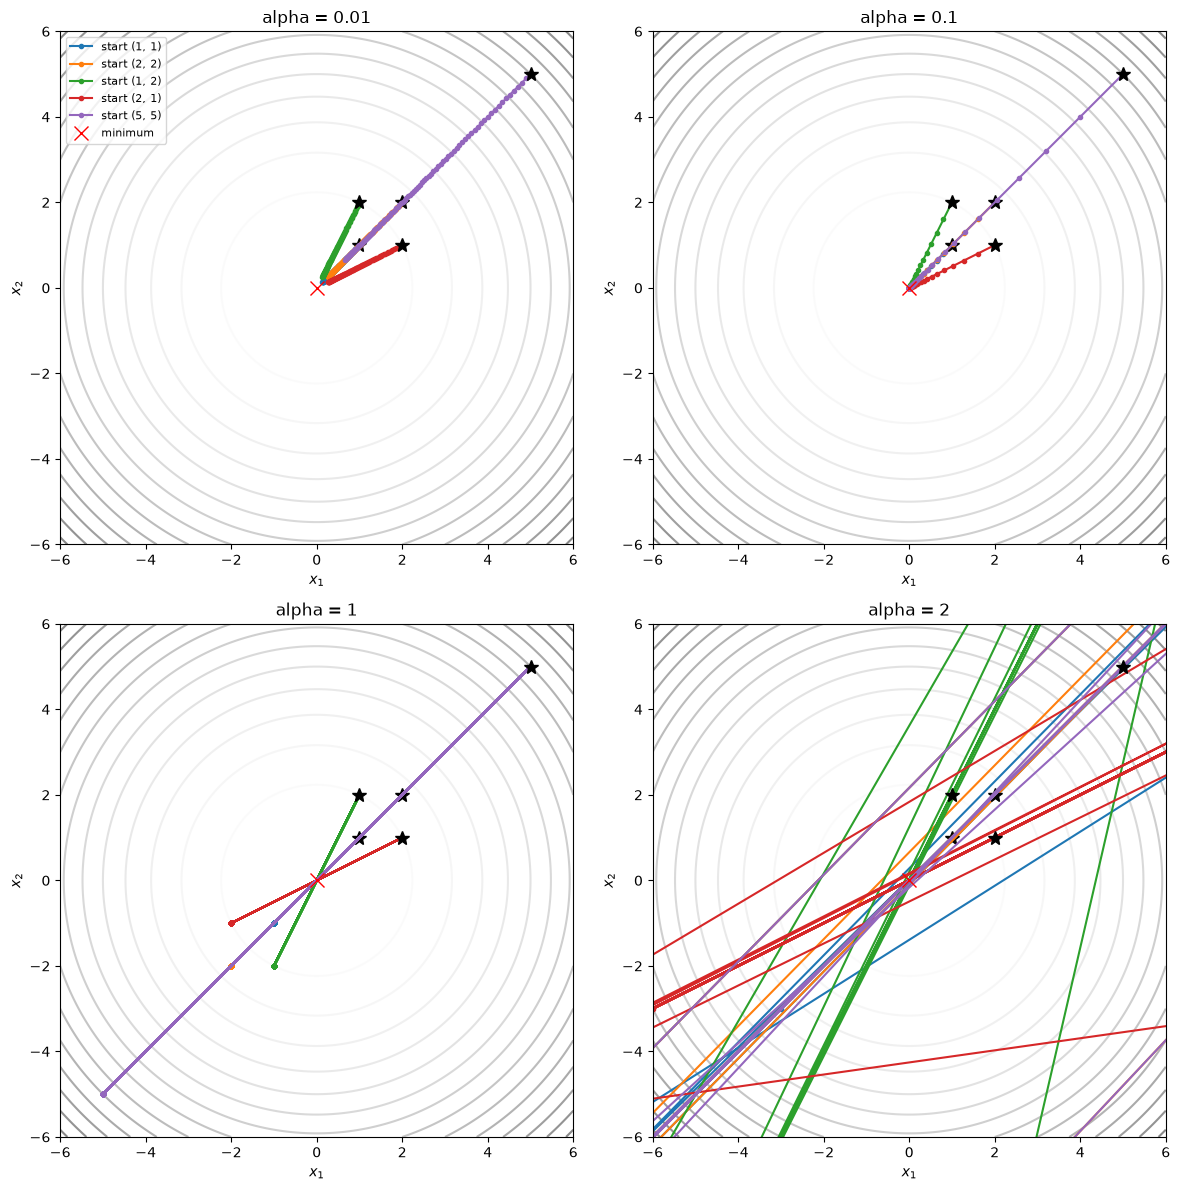

In [248]:
xx = np.linspace(-6, 6, 200)
X1, X2 = np.meshgrid(xx, xx)

fig, axes = plt.subplots(2, 2, figsize=(12, 12))
for ax, a in zip(axes.flat, alpha):
    ax.contour(X1, X2, f(X1, X2), levels=15, cmap="Greys", alpha=0.5)
    for point in initial_points_1:
        path = np.array(gradient_descent(df, point, a, num_iterations[2]))
        ax.plot(path[:, 0], path[:, 1], "o-", markersize=3, label=f"start {point}")
        ax.plot(*point, "k*", markersize=10)
    ax.plot(0, 0, "rx", markersize=10, label="minimum")
    ax.set_xlim(-6, 6)
    ax.set_ylim(-6, 6)
    ax.set_title(f"alpha = {a}")
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.set_aspect("equal")
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()


### 1.1 Questions

**Experiment 1.1.1: constant step $\alpha^k = 0.1$, at most 100 iterations**
For $\alpha^k = 0.1$ we can observe that it approaches to the minimum, the more iterations, the closer to it. We observe a big improvement from 10 iterations to further,the path is straight to the minimum without any bigger oscillations.

**Experiment 1.1.2: larger steps $\alpha^k = 1$ and $\alpha^k = 2$**
The behaviour is different than the previous one, as bigger the step is, we can observe that for $\alpha^k = 1$ the function oscilates between the starting point and the same point in negative values. That's an interesting behaviour, as the function is squared, changing the sign of the point doesn't changes his value. For $\alpha^k = 2$ we see that the algorithm skips the minimum and diverges. To experiment more, we looked to the behaviour of $\alpha^k = 0.01$, this time it takes very small steps, so with a low number of iterations it's still far from the minimum, but it doesn't oscillatesm, but for a large enough number of iterations it reaches the minimums. It's also a straight line to the minimum.


## 1.2 A function with multiple minima

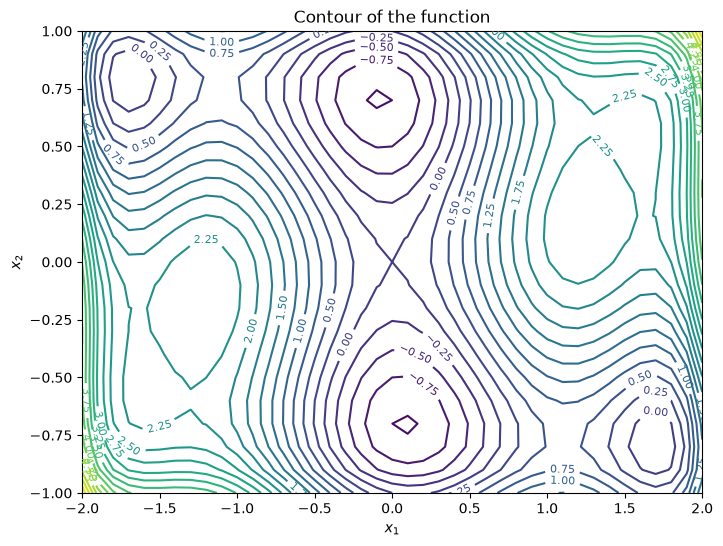

In [249]:
def h(x_1, x_2):
  return x_1**2 * (4-2.1*x_1**2 + (1/3)*x_1**4) + x_1*x_2 + x_2**2 *(-4+4*x_2**2)

def dh(x_1, x_2):
    return np.array([8*x_1-8.4*x_1**3+2*x_1**5+x_2, x_1-8*x_2+16*x_2**3])

x_1 = np.arange(-2, 2+0.1, 0.1)
x_2 = np.arange(-1, 1+0.1, 0.1)
X_1, X_2 = np.meshgrid(x_1, x_2)
Z = h(X_1, X_2)

#Below we draw the countour of h(x_1, x_2):
fig, ax = plt.subplots(figsize=(8, 6))
contour = ax.contour(X_1, X_2, Z, levels=30, cmap='viridis')
ax.clabel(contour, inline=True, fontsize=8)
ax.set_xlabel(r"$x_1$")
ax.set_ylabel(r"$x_2$")
plt.title("Contour of the function")
plt.show()

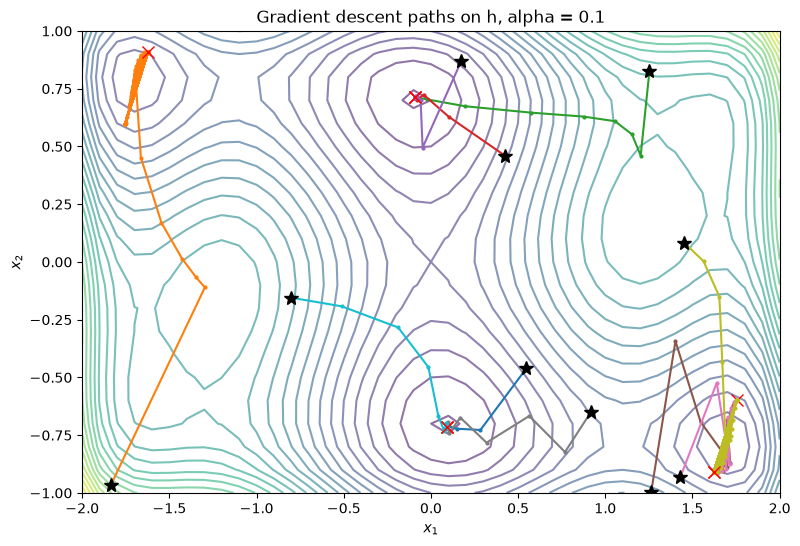

In [250]:
rng = np.random.default_rng(0)  # We establish a fixed seed so we can reproduce the experiments
initial_points_2 = [(rng.uniform(-2, 2), rng.uniform(-1, 1)) for initial_point in range(10)]


fig, ax = plt.subplots(figsize = (9,6))
ax.contour(X_1, X_2, Z, levels = 30, cmap = "viridis", alpha = 0.6)
for point in initial_points_2:
    path = np.array(gradient_descent(dh, point, 0.1, 100))
    if(len(path) <= 100):
        print(f"For starting points = {point}, the number of iterations to reach a minimum is {len(path)-1}")
    ax.plot(path[:,0], path[:,1], "o-", markersize = 2)
    ax.plot(*point, "k*", markersize = 10)
    ax.plot(*path[-1], "rx", markersize=8)    # where each path ends
ax.set_xlim(-2, 2)
ax.set_ylim(-1, 1)
ax.set_xlabel(r"$x_1$")
ax.set_ylabel(r"$x_2$")
ax.set_title("Gradient descent paths on h, alpha = 0.1")
plt.show()

### 1.2.1 Questions
We can observe that depending on the starting point, we get different results, six of them go to the absolute minimums \((-0.09,0.71)\), we know that because of the previous lab and \((0.09,-0.71)\). We observe also that most of the paths move toward the bottom of the nearest valley. The ones that are not converging to the aabsolute minimums seems like they oscillate around a local minimum, similarlly in the previous exercise of the lab (for alpha=1).


In [251]:
def gradient_descent_backtrack(f, df, starting_point):
    
    (x_1, x_2) = starting_point
    points = [(x_1, x_2)]
    while True:
        gradient = df(x_1, x_2)
        if np.linalg.norm(gradient) < 1e-5: # we arbitrarily choose this as tolerance.
            break

        alpha=1
        while f(x_1, x_2) <= f(x_1 - alpha*gradient[0], x_2 - alpha*gradient[1]):
            alpha = alpha/2
        
        x_1 -= alpha*gradient[0]
        x_2 -= alpha*gradient[1]
        points.append((x_1, x_2))

    return points
        

For starting points = (0.5478467492858172, -0.4604265724722594), the number of iterations to reach a minimum is 10
For starting points = (-1.8361059042552212, -0.9669447289429418), the number of iterations to reach a minimum is 11
For starting points = (1.2530809568010897, 0.8255111545554434), the number of iterations to reach a minimum is 12
For starting points = (0.42654310306871945, 0.4589931219679968), the number of iterations to reach a minimum is 9
For starting points = (0.17449996586169148, 0.8701448475755365), the number of iterations to reach a minimum is 9
For starting points = (1.2634142164861286, -0.9945229996597038), the number of iterations to reach a minimum is 16
For starting points = (1.4296171063502774, -0.9328288493890713), the number of iterations to reach a minimum is 17
For starting points = (0.9186217857197763, -0.648688758794882), the number of iterations to reach a minimum is 10
For starting points = (1.4527156893995463, 0.08292244049818343), the number of iter

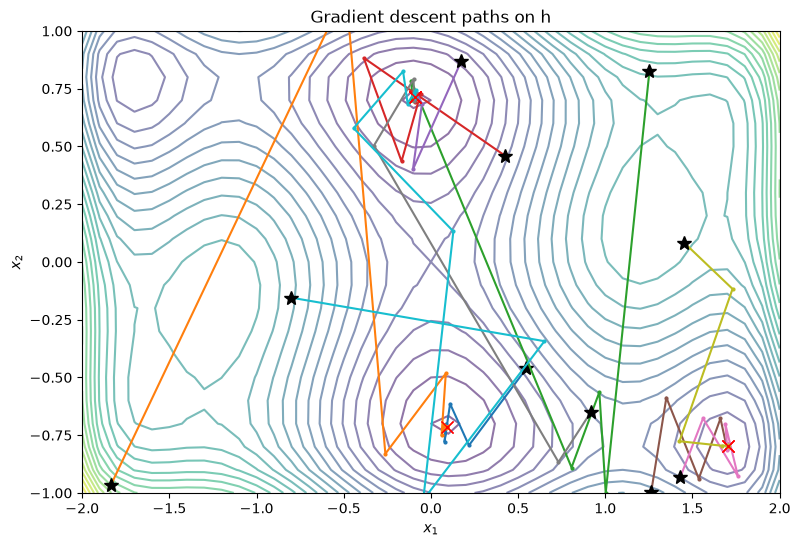

In [252]:

fig, ax = plt.subplots(figsize = (9,6))
ax.contour(X_1, X_2, Z, levels = 30, cmap = "viridis", alpha = 0.6)
for point in initial_points_2:
    path = np.array(gradient_descent_backtrack(h, dh, point))
    print(f"For starting points = {point}, the number of iterations to reach a minimum is {len(path)-1}")
    ax.plot(path[:,0], path[:,1], "o-", markersize = 2)
    ax.plot(*point, "k*", markersize = 10)
    ax.plot(*path[-1], "rx", markersize=8)  
ax.set_xlim(-2, 2)
ax.set_ylim(-1, 1)
ax.set_xlabel(r"$x_1$")
ax.set_ylabel(r"$x_2$")
ax.set_title("Gradient descent paths on h")
plt.show()



### 1.2.2 Questions: backtracking

Stopping criterion: $\|\nabla f(x^{k+1})\| < 10^{-5}$ (or $|f(x^{k+1}) - f(x^k)| < 10^{-3}$).

Thanks to this backtracking algorithm its easy to see that the convergence is better than previous one, because more points go to the minimums, and they don't oscillate perpetually like the previous one. We can see that the number of iterations is small, it's in range 9-17.

1.3 The Rosenbrock function

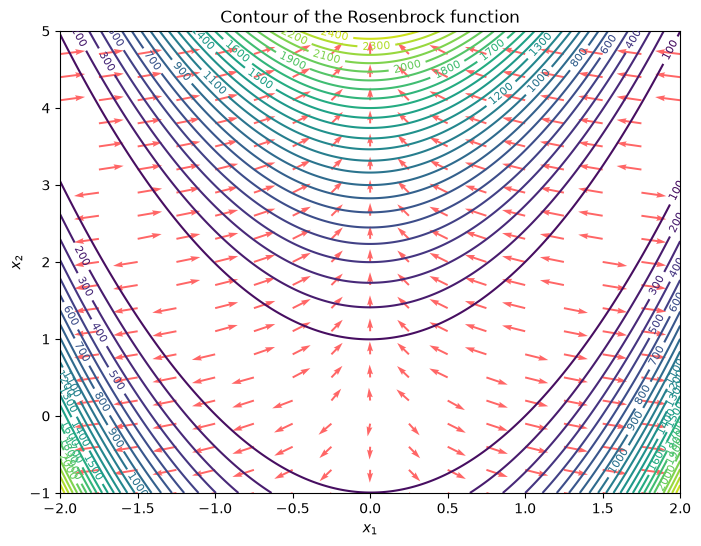

In [253]:
# We define the Rosenbrock function and the gradient
def R(x_1, x_2):
    return (1-x_1)**2 + 100*(x_2 - x_1**2)**2



def dR(x_1, x_2):
    return np.array([-400*x_1*(-x_1**2 + x_2) + 2*x_1 - 2, -200*x_1**2 + 200*x_2])

x_1 = np.arange(-2, 2+0.01, 0.01)
x_2 = np.arange(-1, 5+0.01, 0.01)
X_1, X_2 = np.meshgrid(x_1, x_2)
Z = R(X_1, X_2)

#Below we draw the countour of R(x_1, x_2):
fig, ax = plt.subplots(figsize=(8,6))
contour = ax.contour(X_1, X_2, Z, levels=30, cmap='viridis')
ax.clabel(contour, inline=True, fontsize=8)
ax.set_xlabel(r"$x_1$")
ax.set_ylabel(r"$x_2$")
plt.title("Contour of the Rosenbrock function")

#Draw the gradient information
G_1, G_2 = np.meshgrid(
    np.linspace(-2, 2, 17),
    np.linspace(-1, 5, 21)
)

gradient = dR(G_1, G_2)
norm = np.sqrt(gradient[0]**2 + gradient[1]**2)
norm = np.where(norm == 0, 1, norm)  # Avoid division by zero

ax.quiver(
    G_1, G_2,
    gradient[0] / norm, gradient[1] / norm,
    angles="xy", scale_units="xy", scale=6,
    color="red", alpha=0.6
)

plt.show()

For starting points = (-1.6574033314255026, 0.4208630395765982), the number of iterations to reach the minimum = [1.00000769 1.0000154 ] is 10699, where R(minimum_point) = 5.918400832601506e-11
For starting points = (1.2050978608255876, 2.4929722163862067), the number of iterations to reach the minimum = [1.00000783 1.00001569] is 13861, where R(minimum_point) = 6.140971511499361e-11
For starting points = (-1.6234854310384033, 1.598761641418843), the number of iterations to reach the minimum = [0.99999207 0.99998413] is 11596, where R(minimum_point) = 6.286396955956953e-11
For starting points = (-0.0837948074366639, -0.0415665121775286), the number of iterations to reach the minimum = [0.99999211 0.99998417] is 11984, where R(minimum_point) = 6.251016778250245e-11
For starting points = (0.9383086056368581, -0.31796788047157953), the number of iterations to reach the minimum = [0.99999211 0.9999842 ] is 11928, where R(minimum_point) = 6.233623461889467e-11
For starting points = (-0.4350

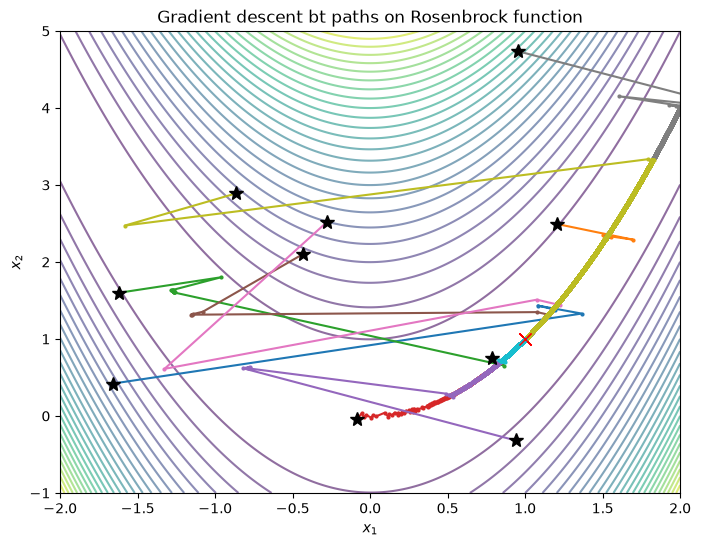

In [254]:
rng = np.random.default_rng(3)  # We establish a fixed seed so we can reproduce the experiments
initial_points_3 = [(rng.uniform(-2, 2), rng.uniform(-1, 5)) for initial_point in range(10)]
fig, ax = plt.subplots(figsize = (8,6))
ax.contour(X_1, X_2, Z, levels = 30, cmap = "viridis", alpha = 0.6)
for point in initial_points_3:
    path = np.array(gradient_descent_backtrack(R, dR, point))
    print(f"For starting points = {point}, the number of iterations to reach the minimum = {(path[-1])} is {len(path)-1}, where R(minimum_point) = {R(path[-1][0], path[-1][1])}")
    ax.plot(path[:,0], path[:,1], "o-", markersize = 2)
    ax.plot(*point, "k*", markersize = 10)
    ax.plot(*path[-1], "rx", markersize=8)    # where each path ends
ax.set_xlim(-2, 2)
ax.set_ylim(-1, 5)
ax.set_xlabel(r"$x_1$")
ax.set_ylabel(r"$x_2$")
ax.set_title("Gradient descent bt paths on Rosenbrock function")
plt.show()

### 1.3 Questions
As we have seen in the theory class this type of function is special because near the minimum the function is almost flat, so the algorithms struggle a bit more to find the minimum, it requires a lot of iterations. The criteria of updating alpha (seen in the fig 1 of the lab) helps to make this method robust, as it makes the steps small and smaller, so it's not skipping the minimum. We can see that we needed +10k of iterations, the algorithm always finded the minimum, with a tolerance.

## 2. Newton Descent Method

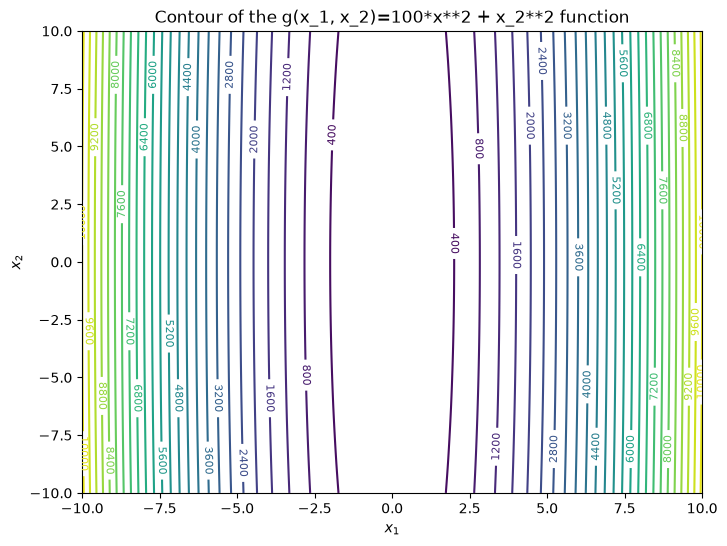

In [255]:
#We define the function, it's gradient and hessian.
def g(x_1, x_2):
    return 100*x_1**2 + x_2**2

def dg(x_1, x_2):
    return np.array([200*x_1, 2*x_2])

def ddg(x_1, x_2):
    return np.array([[200,0],[0,2]])


x_1 = np.arange(-10, 10+0.1, 0.1)
x_2 = np.arange(-10, 10+0.1, 0.1)
X_1, X_2 = np.meshgrid(x_1, x_2)
Z = g(X_1, X_2)

#Below we draw the countour of g(x_1, x_2):
fig, ax = plt.subplots(figsize=(8,6))
contour = ax.contour(X_1, X_2, Z, levels=30, cmap='viridis')
ax.clabel(contour, inline=True, fontsize=8)
ax.set_xlabel(r"$x_1$")
ax.set_ylabel(r"$x_2$")
plt.title("Contour of the g(x_1, x_2)=100*x**2 + x_2**2 function")
plt.show()

For starting points = (8.86112211144735, 0.2265510562872315), the number of iterations to reach the minimum is 496
For starting points = (9.524874114154084, -8.383279522087957), the number of iterations to reach the minimum is 660
For starting points = (2.1471166399005917, -2.4702683124545484), the number of iterations to reach the minimum is 602
For starting points = (6.038024139716146, -6.509443677119431), the number of iterations to reach the minimum is 643
For starting points = (7.432705483753129, 0.8788280152699635), the number of iterations to reach the minimum is 558
For starting points = (8.044301594319766, -0.45692952321587477), the number of iterations to reach the minimum is 528
For starting points = (-1.390074445411738, 5.778934350886589), the number of iterations to reach the minimum is 643
For starting points = (9.683059998622426, -2.605484146951424), the number of iterations to reach the minimum is 607
For starting points = (9.378657386324697, 8.580527755308388), the num

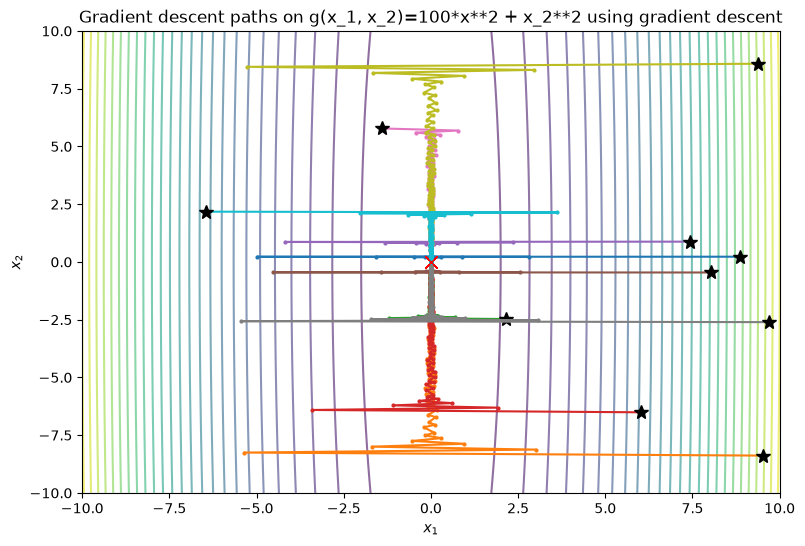

In [256]:
rng = np.random.default_rng(4)  # We establish a fixed seed so we can reproduce the experiments
initial_points_4 = [(rng.uniform(-10, 10), rng.uniform(-10, 10)) for initial_point in range(10)]

fig, ax = plt.subplots(figsize = (9,6))
ax.contour(X_1, X_2, Z, levels = 30, cmap = "viridis", alpha = 0.6)
for point in initial_points_4:
    path = np.array(gradient_descent_backtrack(g, dg, point))
    print(f"For starting points = {point}, the number of iterations to reach the minimum is {len(path)-1}")
    ax.plot(path[:,0], path[:,1], "o-", markersize = 2)
    ax.plot(*point, "k*", markersize = 10)
    ax.plot(*path[-1], "rx", markersize=8)    
ax.set_xlim(-10, 10)
ax.set_ylim(-10, 10)
ax.set_xlabel(r"$x_1$")
ax.set_ylabel(r"$x_2$")
ax.set_title("Gradient descent paths on g(x_1, x_2)=100*x**2 + x_2**2 using gradient descent")
plt.show()


In [257]:
def newton_descent(f, df, ddf, starting_point):
    x_1, x_2 = map(float, starting_point)
    points = [(x_1, x_2)]
    while True:
        gradient = df(x_1, x_2)
        hessian = ddf(x_1, x_2)
        d = np.linalg.solve(hessian, gradient)
        if np.linalg.norm(gradient) < 1e-5:
            break

        alpha = 1 
        while f(x_1, x_2) <= f(x_1-alpha*d[0], x_2 - alpha*d[1]):
            alpha = alpha/2

        x_1 -= alpha*d[0]
        x_2 -= alpha*d[1]
        points.append((x_1, x_2))

    return points


For starting points = (8.86112211144735, 0.2265510562872315), the number of iterations to reach the minimum is 1
For starting points = (9.524874114154084, -8.383279522087957), the number of iterations to reach the minimum is 1
For starting points = (2.1471166399005917, -2.4702683124545484), the number of iterations to reach the minimum is 1
For starting points = (6.038024139716146, -6.509443677119431), the number of iterations to reach the minimum is 1
For starting points = (7.432705483753129, 0.8788280152699635), the number of iterations to reach the minimum is 1
For starting points = (8.044301594319766, -0.45692952321587477), the number of iterations to reach the minimum is 1
For starting points = (-1.390074445411738, 5.778934350886589), the number of iterations to reach the minimum is 1
For starting points = (9.683059998622426, -2.605484146951424), the number of iterations to reach the minimum is 1
For starting points = (9.378657386324697, 8.580527755308388), the number of iteration

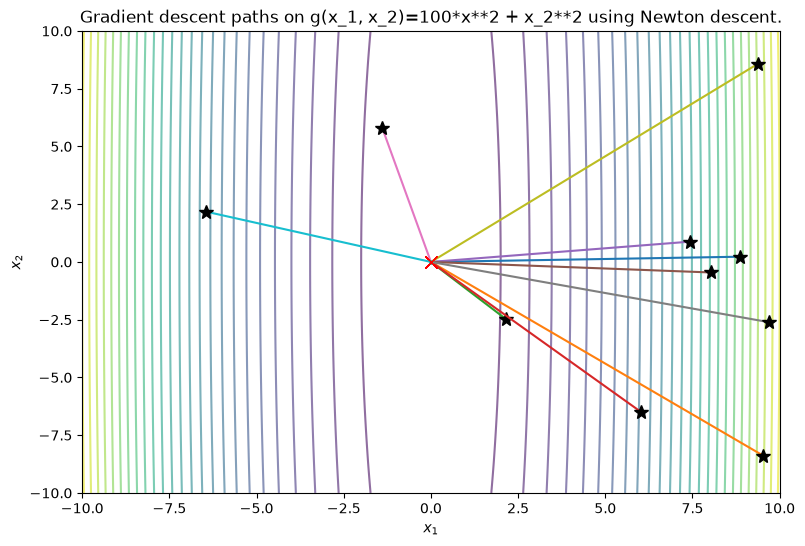

In [258]:
fig, ax = plt.subplots(figsize = (9,6))
ax.contour(X_1, X_2, Z, levels = 30, cmap = "viridis", alpha = 0.6)
for point in initial_points_4:
    path = np.array(newton_descent(g, dg, ddg, point))
    print(f"For starting points = {point}, the number of iterations to reach the minimum is {len(path)-1}")
    ax.plot(path[:,0], path[:,1], "o-", markersize = 2)
    ax.plot(*point, "k*", markersize = 10)
    ax.plot(*path[-1], "rx", markersize=8)    # where each path ends
ax.set_xlim(-10, 10)
ax.set_ylim(-10, 10)
ax.set_xlabel(r"$x_1$")
ax.set_ylabel(r"$x_2$")
ax.set_title("Gradient descent paths on g(x_1, x_2)=100*x**2 + x_2**2 using Newton descent.")
plt.show()

2.1.1 & 2.1.2 & 2.1.3

We see that Gradient Descent with backtracking needs 496-660 iterations to reach the minimum. While the newton descent method reaches the minimum just with one iteration, we see that the gradient path oscillates around the "flat" area, and the step gets smaller and smaller, while the newton descent just goes straight to the point, we can't comment more because it reaches the point in 1 iteration. 

2.2. Function with multiple minima

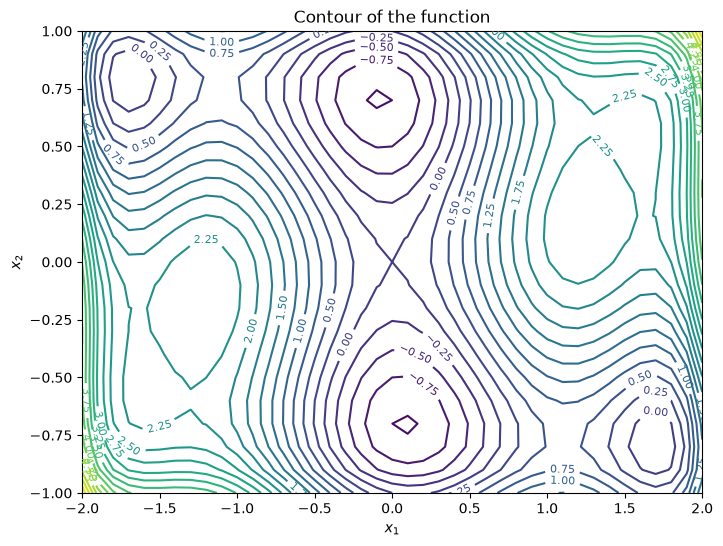

In [259]:
x_1 = np.arange(-2, 2+0.1, 0.1)
x_2 = np.arange(-1, 1+0.1, 0.1)
X_1, X_2 = np.meshgrid(x_1, x_2)
Z = h(X_1, X_2)

#Below we draw the countour of h(x_1, x_2):
fig, ax = plt.subplots(figsize=(8, 6))
contour = ax.contour(X_1, X_2, Z, levels=30, cmap='viridis')
ax.clabel(contour, inline=True, fontsize=8)
ax.set_xlabel(r"$x_1$")
ax.set_ylabel(r"$x_2$")
plt.title("Contour of the function")
plt.show()

For starting points = (-1.8361059042552212, -0.9669447289429418), the number of iterations to reach the minimum is 100, the method is Gradient descent
For starting points = (-1.8361059042552212, -0.9669447289429418), the number of iterations to reach the minimum is 11, the method is Backtracking


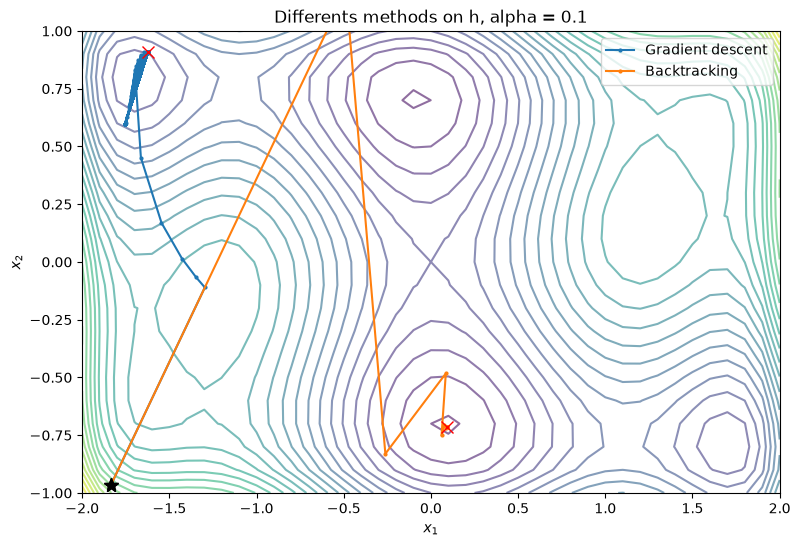

In [ ]:
rng = np.random.default_rng(0)  # We establish a fixed seed so we can reproduce the experiments
initial_points_2 = [(-1.8361059042552212, -0.9669447289429418)]
def ddh(x_1, x_2):
    return np.array([
        [8 - 25.2*x_1**2 + 10*x_1**4, 1],
        [1, -8 + 48*x_2**2]
    ])

methods = [
    ("Gradient descent", lambda p: gradient_descent(dh, p, 0.1, 100)),
    ("Backtracking", lambda p: gradient_descent_backtrack(h, dh, p)),
]


fig, ax = plt.subplots(figsize = (9,6))
ax.contour(X_1, X_2, Z, levels = 30, cmap = "viridis", alpha = 0.6)
for name, method in methods:
    path = np.array(method(initial_points_2[0]))
    print(f"For starting points = {initial_points_2[0]}, the number of iterations to reach the minimum is {len(path)-1}, the method is {name}")
    ax.plot(path[:, 0], path[:, 1], "o-", markersize=2, label=name)
    ax.plot(*initial_points_2[0], "k*", markersize = 10)
    ax.plot(*path[-1], "rx", markersize=8)    
ax.set_xlim(-2, 2)
ax.set_ylim(-1, 1)
ax.set_xlabel(r"$x_1$")
ax.set_ylabel(r"$x_2$")
ax.set_title("Differents methods on h, alpha = 0.1")
ax.legend()  
plt.show()


We can see that each method goes to a different point. The backtracking goes to the global minimum, the gradient descent oscillates as we comented before.

In [261]:
def newton_descent_mod(f, df, ddf, starting_point):
    x_1, x_2 = map(float, starting_point)
    points = [(x_1, x_2)]
    colors = []

    while True:
        gradient = df(x_1, x_2)

        if np.linalg.norm(gradient) < 1e-5:
            break

        hessian = ddf(x_1, x_2)

        if np.all(np.linalg.eigvalsh(hessian) > 0):
            d = np.linalg.solve(hessian, gradient)
            colors.append("green")
        else:
            d = gradient
            colors.append("red")

        alpha = 1
        while f(x_1, x_2) <= f(x_1-alpha*d[0], x_2-alpha*d[1]):
            alpha /= 2

        x_1 -= alpha*d[0]
        x_2 -= alpha*d[1]
        points.append((x_1, x_2))

    return np.array(points), colors

For starting points = (0.5478467492858172, -0.4604265724722594), the number of iterations is 4
For starting points = (-1.8361059042552212, -0.9669447289429418), the number of iterations is 5
For starting points = (1.2530809568010897, 0.8255111545554434), the number of iterations is 7
For starting points = (0.42654310306871945, 0.4589931219679968), the number of iterations is 4
For starting points = (0.17449996586169148, 0.8701448475755365), the number of iterations is 4
For starting points = (1.2634142164861286, -0.9945229996597038), the number of iterations is 6
For starting points = (1.4296171063502774, -0.9328288493890713), the number of iterations is 5
For starting points = (0.9186217857197763, -0.648688758794882), the number of iterations is 6
For starting points = (1.4527156893995463, 0.08292244049818343), the number of iterations is 6
For starting points = (-0.8011524378504609, -0.1546255576046831), the number of iterations is 7


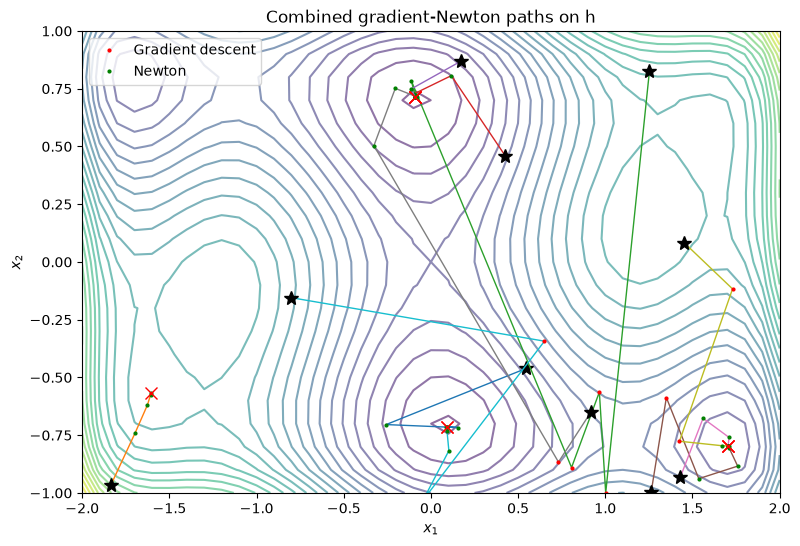

In [262]:
initial_points_2 = [(rng.uniform(-2, 2), rng.uniform(-1, 1)) for initial_point in range(10)]

fig, ax = plt.subplots(figsize=(9, 6))
ax.contour(X_1, X_2, h(X_1, X_2), levels=30,
           cmap="viridis", alpha=0.6)

for point in initial_points_2:
    path, colors = newton_descent_mod(h, dh, ddh, point)
    path = np.array(path)

    print(
        f"For starting points = {point}, "
        f"the number of iterations is {len(path)-1}"
    )

    ax.plot(path[:, 0], path[:, 1], "-", linewidth=1)

    for k, color in enumerate(colors):
        ax.plot(path[k, 0], path[k, 1], "o", color=color, markersize=2)

    ax.plot(*point, "k*", markersize=10)
    ax.plot(*path[-1], "rx", markersize=8)

ax.plot([], [], "ro", markersize=2, label="Gradient descent")
ax.plot([], [], "go", markersize=2, label="Newton")

ax.set_xlim(-2, 2)
ax.set_ylim(-1, 1)
ax.set_xlabel(r"$x_1$")
ax.set_ylabel(r"$x_2$")
ax.set_title("Combined gradient-Newton paths on h")
ax.legend()
plt.show()

Combined gradient-Newton: starting point = (0.5478467492858172, -0.4604265724722594), iterations = 4
Combined gradient-Newton: starting point = (-1.8361059042552212, -0.9669447289429418), iterations = 5
Combined gradient-Newton: starting point = (1.2530809568010897, 0.8255111545554434), iterations = 7
Combined gradient-Newton: starting point = (0.42654310306871945, 0.4589931219679968), iterations = 4
Combined gradient-Newton: starting point = (0.17449996586169148, 0.8701448475755365), iterations = 4
Combined gradient-Newton: starting point = (1.2634142164861286, -0.9945229996597038), iterations = 6
Combined gradient-Newton: starting point = (1.4296171063502774, -0.9328288493890713), iterations = 5
Combined gradient-Newton: starting point = (0.9186217857197763, -0.648688758794882), iterations = 6
Combined gradient-Newton: starting point = (1.4527156893995463, 0.08292244049818343), iterations = 6
Combined gradient-Newton: starting point = (-0.8011524378504609, -0.1546255576046831), itera

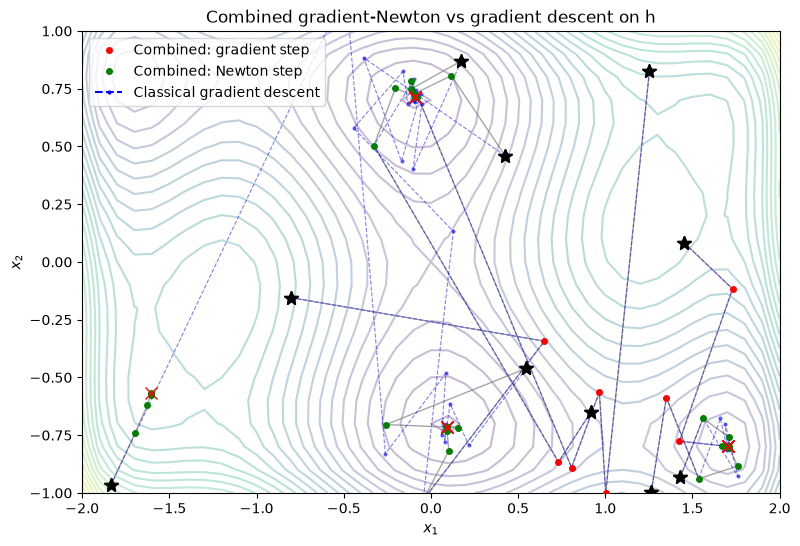

In [263]:
rng = np.random.default_rng(0)  
initial_points_2 = [(rng.uniform(-2, 2), rng.uniform(-1, 1))
                    for initial_point in range(10)]

fig, ax = plt.subplots(figsize=(9, 6))
ax.contour(X_1, X_2, h(X_1, X_2), levels=30,
           cmap="viridis", alpha=0.3)

for point in initial_points_2:
    path, colors = newton_descent_mod(h, dh, ddh, point)
    path = np.array(path)

    print(
        f"Combined gradient-Newton: starting point = {point}, "
        f"iterations = {len(path)-1}"
    )

    ax.plot(path[:, 0], path[:, 1], "-", color="gray",
            linewidth=1, alpha=0.7)

    for k, color in enumerate(colors):
        ax.plot(path[k, 0], path[k, 1], "o",
                color=color, markersize=4, zorder=3)

    ax.plot(*point, "k*", markersize=10, zorder=4)
    ax.plot(*path[-1], "rx", markersize=8, zorder=4)

for point in initial_points_2:
    path_aux = gradient_descent_backtrack(h, dh, point)
    path_aux = np.array(path_aux)

    print(
        f"Classical gradient descent: starting point = {point}, "
        f"iterations = {len(path_aux)-1}"
    )

    ax.plot(path_aux[:, 0], path_aux[:, 1], "o--",
            color="blue", markersize=2, linewidth=0.8, alpha=0.5)

    ax.plot(*point, "k*", markersize=10, zorder=4)
    ax.plot(*path_aux[-1], "rx", markersize=8, zorder=4)

ax.plot([], [], "ro", markersize=4, label="Combined: gradient step")
ax.plot([], [], "go", markersize=4, label="Combined: Newton step")
ax.plot([], [], "bo--", markersize=2, label="Classical gradient descent")

ax.set_xlim(-2, 2)
ax.set_ylim(-1, 1)
ax.set_xlabel(r"$x_1$")
ax.set_ylabel(r"$x_2$")
ax.set_title("Combined gradient-Newton vs gradient descent on h")
ax.legend()
plt.show()

2.2.2 & 2.2.3

In the gradient descent we saw that we need between 9 to 17 iterations to reach the minimum, while in the combined methon we only needed to 4-7 iterations, considerably less. We can also observe that near the minimums, newton method is used because the Hessian is positive definite.

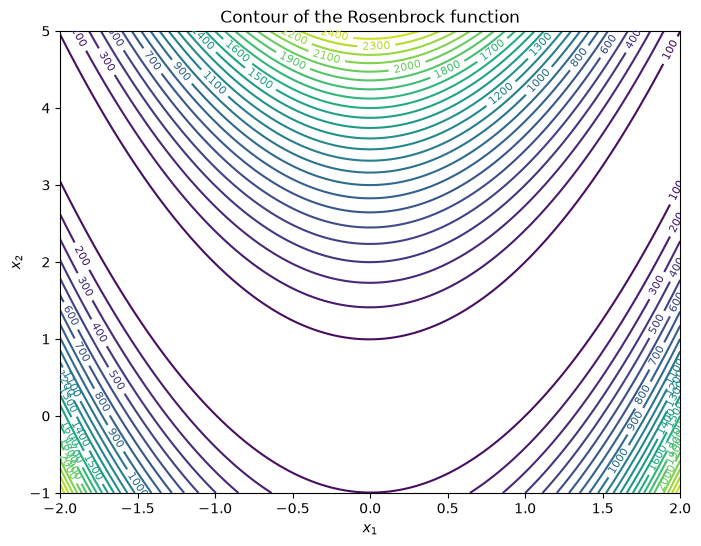

In [264]:
# we define the functions
def R(x_1, x_2):
    return (1-x_1)**2 + 100*(x_2 - x_1**2)**2



def dR(x_1, x_2):
    return np.array([-400*x_1*(-x_1**2 + x_2) + 2*x_1 - 2, -200*x_1**2 + 200*x_2])

x_1 = np.arange(-2, 2+0.01, 0.01)
x_2 = np.arange(-1, 5+0.01, 0.01)
X_1, X_2 = np.meshgrid(x_1, x_2)
Z = R(X_1, X_2)

#Below we draw the countour of R(x_1, x_2):
fig, ax = plt.subplots(figsize=(8,6))
contour = ax.contour(X_1, X_2, Z, levels=30, cmap='viridis')
ax.clabel(contour, inline=True, fontsize=8)
ax.set_xlabel(r"$x_1$")
ax.set_ylabel(r"$x_2$")
plt.title("Contour of the Rosenbrock function")
plt.show()

Gradient descent: starting points = (-1.6574033314255026, 0.4208630395765982), number of iterations to reach the minimum = [1.00000769 1.0000154 ] is 10699, R(minimum_point) = 5.918400832601506e-11
Newton method: starting points = (-1.6574033314255026, 0.4208630395765982), number of iterations to reach the minimum = [0.99999995 0.99999989] is 22, R(minimum_point) = 2.913194344672571e-15

Gradient descent: starting points = (1.2050978608255876, 2.4929722163862067), number of iterations to reach the minimum = [1.00000783 1.00001569] is 13861, R(minimum_point) = 6.140971511499361e-11
Newton method: starting points = (1.2050978608255876, 2.4929722163862067), number of iterations to reach the minimum = [1.00000002 1.00000005] is 13, R(minimum_point) = 1.85213692251696e-15

Gradient descent: starting points = (-1.6234854310384033, 1.598761641418843), number of iterations to reach the minimum = [0.99999207 0.99998413] is 11596, R(minimum_point) = 6.286396955956953e-11
Newton method: starting 

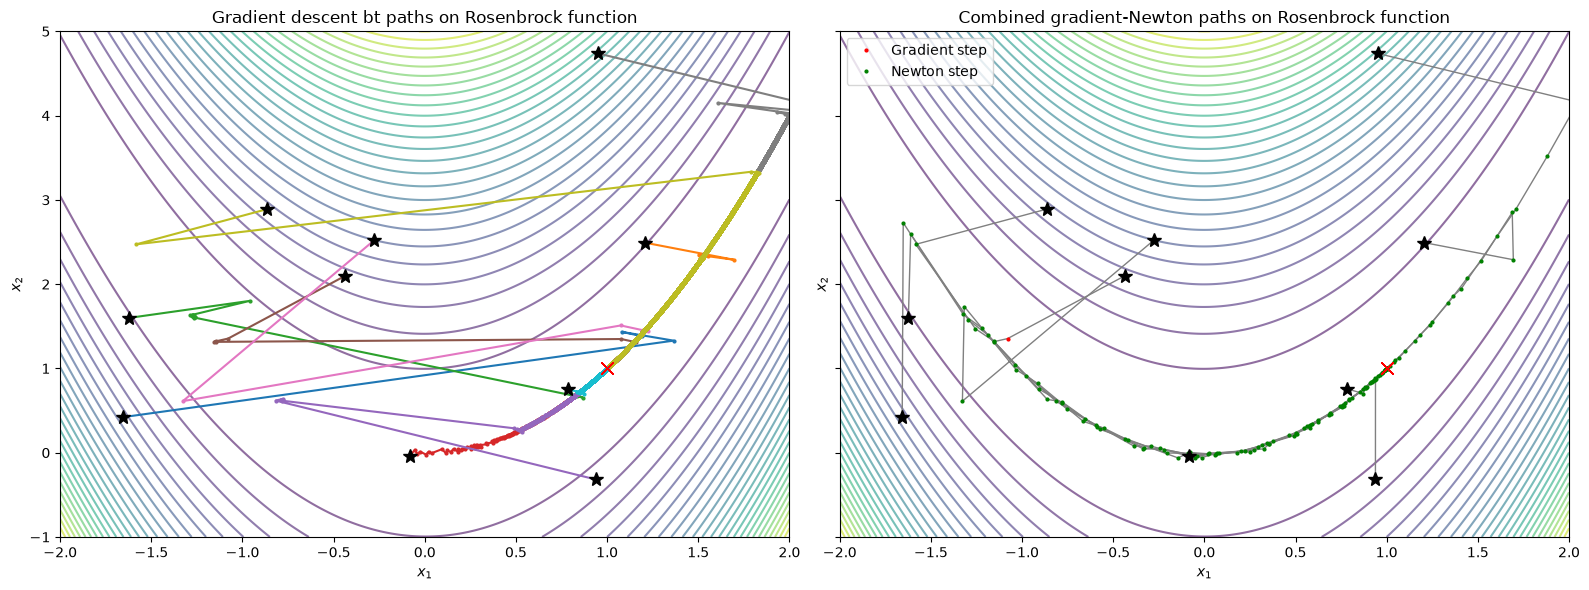

In [ ]:
def ddR(x_1, x_2):
    return np.array([
        [1200*x_1**2 - 400*x_2 + 2, -400*x_1],
        [-400*x_1, 200]
    ])

rng = np.random.default_rng(3)  # We establish a fixed seed so we can reproduce the experiments
initial_points_3 = [(rng.uniform(-2, 2), rng.uniform(-1, 5)) for initial_point in range(10)]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6),
                               sharex=True, sharey=True)
ax1.contour(X_1, X_2, Z, levels = 30, cmap = "viridis", alpha = 0.6)
ax2.contour(X_1, X_2, Z, levels = 30, cmap = "viridis", alpha = 0.6)
for point in initial_points_3:
    path = np.array(gradient_descent_backtrack(R, dR, point))
    path_aux, colors = newton_descent_mod(R, dR, ddR, point)
    path_aux = np.array(path_aux)
    print(f"Gradient descent: starting points = {point}, number of iterations to reach the minimum = {(path[-1])} is {len(path)-1}, R(minimum_point) = {R(path[-1][0], path[-1][1])}")
    print(f"Newton method: starting points = {point}, number of iterations to reach the minimum = {(path_aux[-1])} is {len(path_aux)-1}, R(minimum_point) = {R(path_aux[-1][0], path_aux[-1][1])}")
    print()
    ax1.plot(path[:, 0], path[:, 1], "o-", markersize=2)
    ax1.plot(*point, "k*", markersize=10, zorder=4)
    ax1.plot(*path[-1], "rx", markersize=8, zorder=4)

    ax2.plot(path_aux[:, 0], path_aux[:, 1], "-", color="gray", linewidth=1)

    for k, color in enumerate(colors):
        ax2.plot(path_aux[k, 0], path_aux[k, 1], "o",
                 color=color, markersize=2, zorder=3)

    ax2.plot(*point, "k*", markersize=10, zorder=4)
    ax2.plot(*path_aux[-1], "rx", markersize=8, zorder=4)    # where each path ends
for ax in (ax1, ax2):
    ax.set_xlim(-2, 2)
    ax.set_ylim(-1, 5)
    ax.set_xlabel(r"$x_1$")
    ax.set_ylabel(r"$x_2$")
ax1.set_title("Gradient descent bt paths on Rosenbrock function")
ax2.set_title("Combined gradient-Newton paths on Rosenbrock function")

ax2.plot([], [], "ro", markersize=2, label="Gradient step")
ax2.plot([], [], "go", markersize=2, label="Newton step")
ax2.legend()

plt.tight_layout()
plt.show()

We can observe that gradient descent requires more than 10k iterations to reach the minimum, on the other hand, the combined Newton-gradient method needs between 3-23 iterations. We can also observe that Gradient descent oscillates from side to side and then moves slowly along the valley, while the Newton method follows the valley straight to the minimum. 